# 01 — Exploratory Data Analysis

Quick EDA of the LendingClub loan-granting dataset (`data/raw/LC_loans_granting_model_dataset.csv`).

**Target:** `Default` (1 = borrower defaulted, 0 = repaid).

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
cfg = yaml.safe_load((ROOT / 'configs/config.yaml').read_text())
TARGET = cfg['data']['target']

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:,.3f}'.format)

df = pd.read_csv(ROOT / cfg['paths']['raw_data'] / cfg['data']['raw_file'], low_memory=False)
df.shape

(1347681, 15)

## 1. Overview

In [3]:
df.columns.tolist()

['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'Default', 'title', 'desc']

In [4]:
pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'missing_pct': (df.isna().mean() * 100).round(2),
})

,dtype,n_unique,missing_pct
id,int64,1347681,0.000
issue_d,str,139,0.000
revenue,float64,65608,0.000
dti_n,float64,7068,0.000
loan_amnt,int64,1560,0.000
fico_n,float64,48,0.000
experience_c,int64,2,0.000
emp_length,str,12,0.000
purpose,str,14,0.000
home_ownership_n,str,4,0.000


In [5]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate ids :', df['id'].duplicated().sum())

Duplicate rows: 0
Duplicate ids : 0


## 2. Target balance

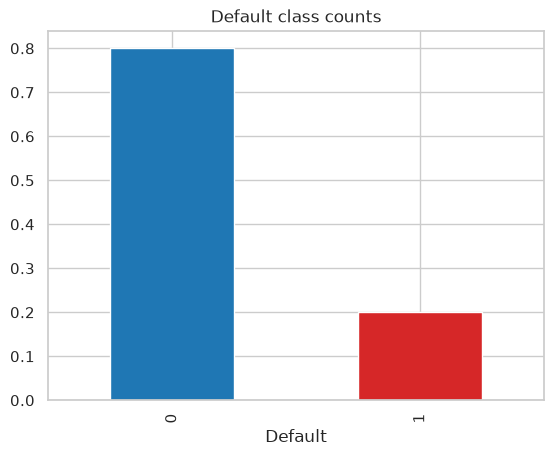

Default
0   0.800
1   0.200
Name: share, dtype: float64

In [6]:
ax = df[TARGET].value_counts(normalize=True).plot.bar(color=['tab:blue', 'tab:red'])
ax.set_title('Default class counts'); ax.set_xlabel(TARGET); plt.show()
df[TARGET].value_counts(normalize=True).rename('share')

## 3. Numeric features

In [8]:
num_cols = ['revenue', 'dti_n', 'loan_amnt', 'fico_n']
df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
revenue,"1,347,681.000","77,369.683","70,362.990","1,896.000","19,000.000","46,600.000","65,000.000","92,000.000","260,000.000","10,999,200.000"
dti_n,"1,347,681.000",18.299,11.152,0.000,1.800,11.820,17.630,24.070,38.480,999.000
loan_amnt,"1,347,681.000","14,408.230","8,715.347",500.000,"1,500.000","7,975.000","12,000.000","20,000.000","35,000.000","40,000.000"
fico_n,"1,347,681.000",698.159,31.849,612.000,662.000,672.000,692.000,712.000,802.000,847.500


In [ ]:
# Outlier / invalid-value checks
pd.Series({
    'revenue == 0': (df['revenue'] == 0).sum(),
    'revenue > 1M': (df['revenue'] > 1_000_000).sum(),
    'dti_n < 0': (df['dti_n'] < 0).sum(),
    'dti_n > 100': (df['dti_n'] > 100).sum(),
    'dti_n == 999': (df['dti_n'] == 999).sum(),
})

revenue == 0      0
revenue > 1M    294
dti_n < 0         0
dti_n > 100     533
dti_n == 999     38
dtype: int64

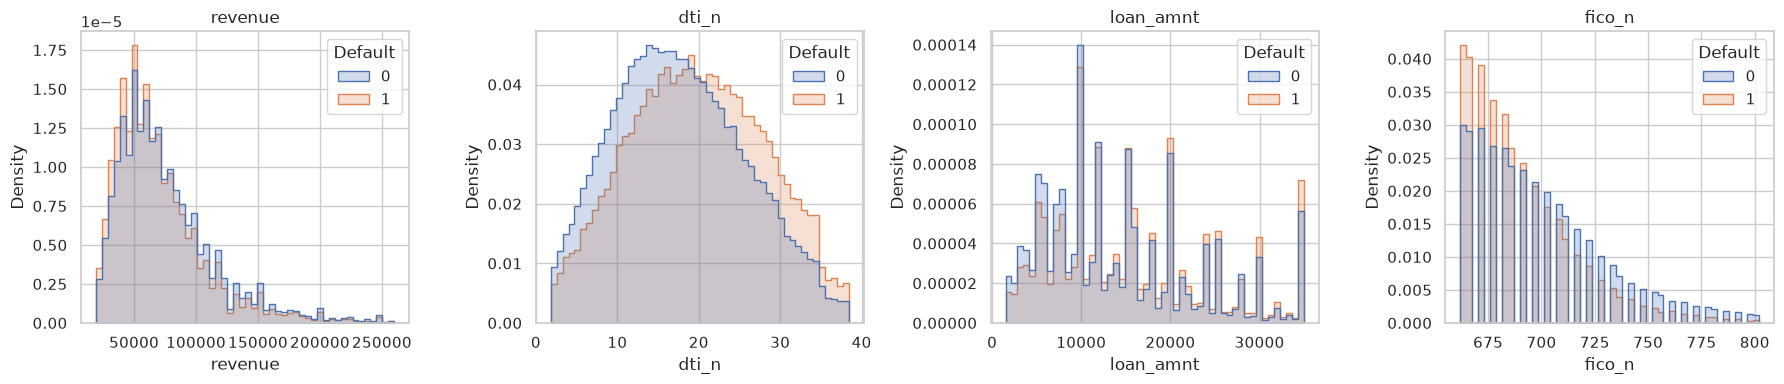

In [ ]:
# Distributions by target (clipped at 1st/99th percentile for readability)
sample = df.sample(200_000, random_state=42)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    lo, hi = df[col].quantile([.01, .99])
    s = sample[sample[col].between(lo, hi)]
    sns.histplot(data=s, x=col, hue=TARGET, stat='density', common_norm=False,
                 bins=50, element='step', ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

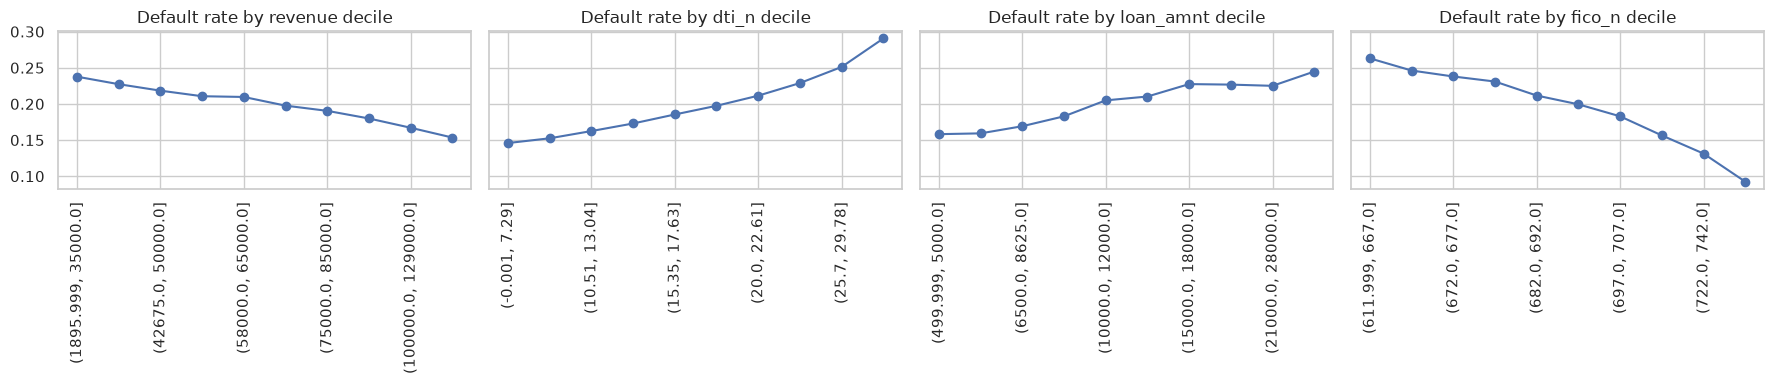

In [ ]:
# Default rate by numeric-feature decile
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, col in zip(axes, num_cols):
    bins = pd.qcut(df[col], 10, duplicates='drop')
    df.groupby(bins, observed=True)[TARGET].mean().plot(marker='o', ax=ax)
    ax.set_title(f'Default rate by {col} decile'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()

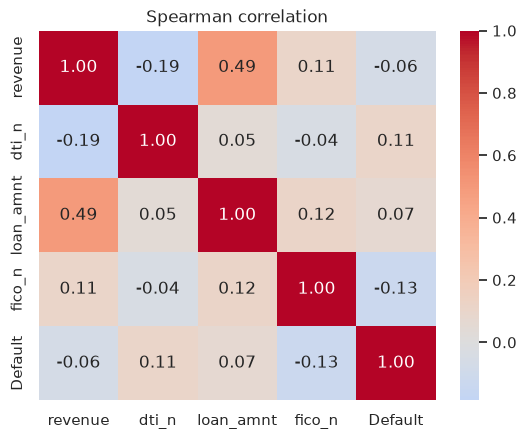

In [ ]:
sns.heatmap(df[num_cols + [TARGET]].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='coolwarm', center=0)
plt.title('Spearman correlation'); plt.show()

## 4. Categorical features

In [ ]:
def default_rate(col, top=None):
    t = df.groupby(col)[TARGET].agg(n='size', default_rate='mean').sort_values('n', ascending=False)
    return t.head(top) if top else t

for col in ['emp_length', 'home_ownership_n', 'purpose', 'experience_c']:
    display(default_rate(col))

,n,default_rate
emp_length,,
10+ years,442667,0.188
2 years,122091,0.198
< 1 year,108517,0.205
3 years,107862,0.200
1 year,88841,0.206
5 years,84326,0.196
4 years,80761,0.198
NI,78188,0.270
6 years,62877,0.194


,n,default_rate
home_ownership_n,,
MORTGAGE,666594,0.172
RENT,535585,0.232
OWN,144985,0.206
OTHER,517,0.197


,n,default_rate
purpose,,
debt_consolidation,781206,0.212
credit_card,295551,0.169
home_improvement,87684,0.178
other,78263,0.211
major_purchase,29543,0.186
medical,15606,0.218
small_business,15575,0.299
car,14647,0.147
moving,9520,0.234


,n,default_rate
experience_c,,
1,1347656,0.200
0,25,0.120


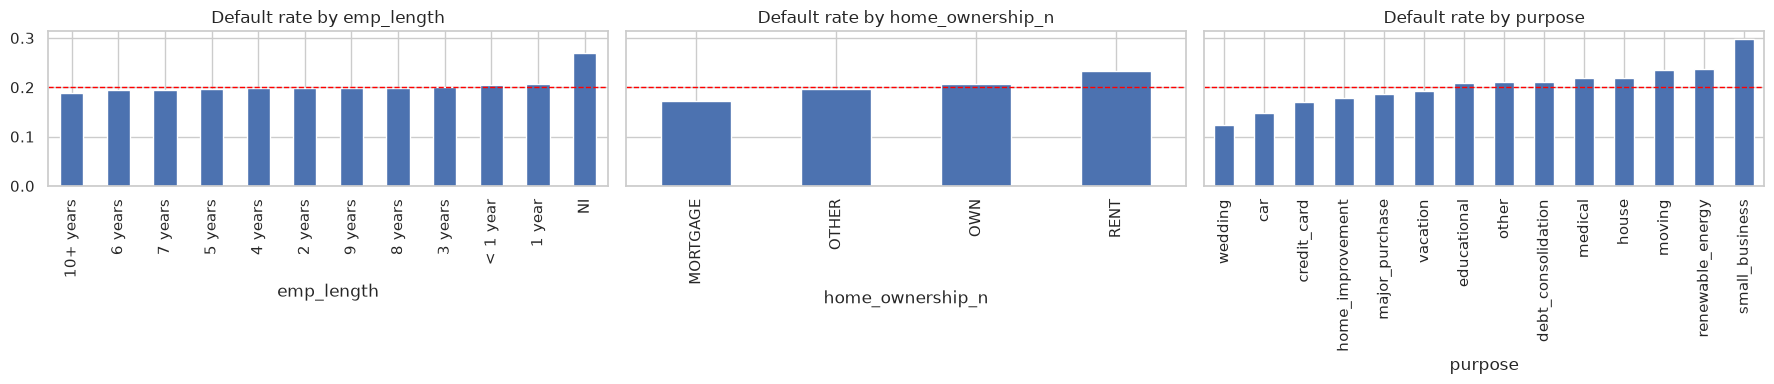

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, col in zip(axes, ['emp_length', 'home_ownership_n', 'purpose']):
    default_rate(col)['default_rate'].sort_values().plot.bar(ax=ax)
    ax.axhline(df[TARGET].mean(), color='red', ls='--', lw=1)
    ax.set_title(f'Default rate by {col}')
plt.tight_layout(); plt.show()

In [ ]:
# High-cardinality columns
state = default_rate('addr_state')
print('addr_state: ', df['addr_state'].nunique(), 'levels; default rate range',
      state['default_rate'].round(3).agg(['min', 'max']).tolist())
print('zip_code:   ', df['zip_code'].nunique(), 'levels')
print('title:      ', df['title'].nunique(), 'levels')
print('desc:       ', f"{df['desc'].isna().mean():.1%} missing")

addr_state:  51 levels; default rate range [0.132, 0.261]
zip_code:    945 levels
title:       61451 levels
desc:        91.2% missing


## 5. Time dimension (`issue_d`)

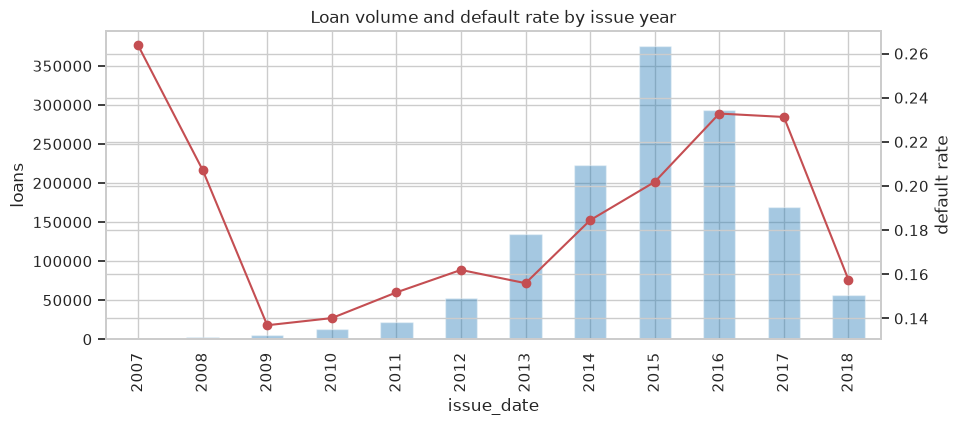

,n,default_rate
issue_date,,
2007,599,0.264
2008,2393,0.207
2009,5281,0.137
2010,12537,0.140
2011,21721,0.152
2012,53367,0.162
2013,134804,0.156
2014,223102,0.184
2015,375543,0.202


In [ ]:
df['issue_date'] = pd.to_datetime(df['issue_d'], format='%b-%Y')
by_year = df.groupby(df['issue_date'].dt.year)[TARGET].agg(n='size', default_rate='mean')
fig, ax1 = plt.subplots(figsize=(10, 4))
by_year['n'].plot.bar(ax=ax1, alpha=.4, color='tab:blue'); ax1.set_ylabel('loans')
ax2 = ax1.twinx(); ax2.plot(range(len(by_year)), by_year['default_rate'], 'r-o'); ax2.set_ylabel('default rate')
plt.title('Loan volume and default rate by issue year'); plt.show()
by_year

## 6. Key findings

**Data quality**
- 1,347,681 loans × 15 columns, no duplicate rows or ids.
- Missing values only in free text: `title` (1.2%) and `desc` (91.2%).
- `emp_length` uses `NI` (not informed) for 78k rows (5.8%) instead of NaN.
- Outliers: `dti_n` has 533 rows > 100, including 38 at the placeholder value 999. `revenue` has 294 rows > $1M (max $11M). Both should be capped or cleaned.

**Target**
- `Default` is imbalanced: 80% repaid / 20% default. Use stratified splits and ROC-AUC / PR-AUC rather than accuracy.

**Signal in the features** (default rate, lowest → highest decile; Spearman ρ with target)
| feature | lowest decile | highest decile | ρ |
|---|---|---|---|
| `fico_n` | 26.3% | 9.2% | −0.13 |
| `dti_n` | 14.6% | 29.0% | +0.11 |
| `loan_amnt` | 15.8% | 24.5% | +0.07 |
| `revenue` | 23.8% | 15.3% | −0.06 |

- FICO is the strongest single predictor, then DTI. All relationships are monotonic, so tree models and logistic regression on binned or scaled features should both work.
- `home_ownership_n`: RENT defaults at 23.2% vs MORTGAGE at 17.2%.
- `purpose`: small_business is the riskiest (29.9%); wedding (12.4%) and car (14.7%) are the safest.
- `emp_length`: almost flat (19–21%), **except `NI` at 27.0%**, so missing employment info is itself a risk signal.
- `addr_state` default rate ranges 13.2%–26.1% and is worth target-encoding. `zip_code` (945 levels) is high-cardinality.
- `experience_c` is nearly constant (only 25 zeros), so drop it.

**Time / leakage risks**
- Loans span 2007–2018, peaking in 2015. Default rate rises from ~14% (2009–10) to ~23% (2016–17), then drops to 15.8% in 2018. The 2018 drop most likely means **those loans haven't had time to default yet**. Consider excluding immature vintages or using a time-based split (train on older, validate on newer).
- `id` is a row identifier and should be dropped. `issue_d` is useful for splitting, not as a raw feature.
- `title` (61k levels) mostly duplicates `purpose`, and `desc` is 91% empty. Drop both, or treat them as optional text features later.
